<a href="https://colab.research.google.com/github/hudaalsaedi/feature-31-colab-update/blob/main/Fake_News_Detecion_Ghadoof_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Fake News Detecion**

# **Step 1: Machine Learning Models**

**Task 1.1 — Load and Explore**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import re

**Load the dataset with pandas**

In [ ]:
true = pd.read_csv("/content/true.csv", engine="python", encoding="utf-8", on_bad_lines='skip')
fake = pd.read_csv("/content/fake.csv", engine="python", encoding="utf-8", on_bad_lines='skip')

**print the first few rows**

In [ ]:
true.head()
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


**Check the shape**

In [ ]:
print(true.shape)
print(fake.shape)

(2479, 4)
(2387, 4)


**Check for missing values**

There are no missing values

In [ ]:
true.isnull().sum()

,0
title,0
text,0
subject,0
date,0


In [ ]:
fake.isnull().sum()

,0
title,0
text,0
subject,0
date,0


**Check class balance**

The data is balanced

In [ ]:
df_true = true.copy()
df_true["label"] = 1

df_fake = fake.copy()
df_fake["label"] = 0

df = pd.concat([df_true, df_fake], axis=0)

print("label counts:", df["label"].value_counts().to_dict())

label counts: {1: 2479, 0: 2387}


**Task 1.2 — Prepare the Data**

Separate features (X) and label (y)

Split into train (80%) and test (20%) sets — use random_state=42

In [ ]:
def clean(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean)

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)


**Task 1.3 — Train and Compare Models**

**Train at least 3 models**

In [ ]:
#Logistic Regression
model_lr = LogisticRegression(max_iter=2000)
model_lr.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=2000)

In [ ]:
#Random Forest
model = RandomForestClassifier(random_state=42)
model.fit(X_train_tfidf, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
#KNN
model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(X_train_tfidf, y_train)

KNeighborsClassifier()

**For each model report: accuracy, precision, recall, F1-score**

In [ ]:
y_pred = model_lr.predict(X_test_tfidf)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
print("Accuracy:", acc)
print("Precision:", prec)
print("Recall:", rec)
print("F1-score:", f1)

Accuracy: 0.9907597535934292
Precision: 0.9840954274353877
Recall: 0.9979838709677419
F1-score: 0.990990990990991


**Plot a confusion matrix for each model**

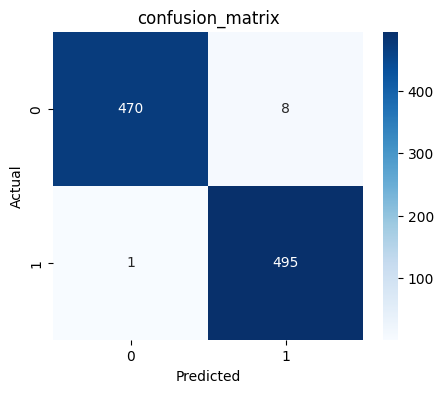

In [ ]:
def plot_cm(model, X_test, y_test, title):
    y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("confusion_matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Put all results in one summary table and choose the best model**

In [ ]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_test_binary = y_test.astype(int)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)

    return {
        "Model": name,
        "Accuracy": round(acc, 3),
        "Precision": round(prec, 3),
        "Recall": round(rec, 3),
        "F1-score": round(f1, 3)
    }

results = []

results.append(evaluate_model(model_lr,  X_test_tfidf, y_test, "Logistic Regression"))
results.append(evaluate_model(model,  X_test_tfidf, y_test, "Random Forest"))
results.append(evaluate_model(model_knn, X_test_tfidf, y_test, "KNN"))

df_results = pd.DataFrame(results)
df_results
# Random Forest
#هو الافضل؛بسبب حصوله على اعلى F1، أعلى Recall،أعلى Accuracy،نموذج قوي جدًا مع TF‑IDF،وافضل اداء شامل

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.991,0.984,0.998,0.991
1,Random Forest,0.998,0.998,0.998,0.998
2,KNN,0.910,0.878,0.956,0.915


# **Step 2: Neural Network**

In [ ]:
# دمج البيانات
df_true = true.copy()
df_true["label"] = 1

df_fake = fake.copy()
df_fake["label"] = 0

df = pd.concat([df_true, df_fake], axis=0)

# تقسيم البيانات
X = df["text"]
y = df["label"]

vectorizer = TfidfVectorizer(max_features=5000)
X_vec = vectorizer.fit_transform(X)
#حولنا النصوص لارقام

X_train, X_test, y_train, y_test = train_test_split(
    X_vec, y, test_size=0.2, random_state=42)

In [ ]:
# بنينا ال NN
model = models.Sequential([
    layers.Input(shape=(5000,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")])


#استعملنا ادم لانو افضل شي
#نعد النموذج للتدريب
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"])

In [ ]:
#ندرب النموذج
history = model.fit(
    X_train.toarray(), y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32)

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9284 - loss: 0.2930 - val_accuracy: 0.9872 - val_loss: 0.0460
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9955 - loss: 0.0190 - val_accuracy: 0.9923 - val_loss: 0.0261
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 0.9923 - val_loss: 0.0282
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 0.9923 - val_loss: 0.0254
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 8.7858e-04 - val_accuracy: 0.9923 - val_loss: 0.0272
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 7.3722e-04 - val_accuracy: 0.9936 - val_loss: 0.0267
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 4.7587e-04 - val_accuracy: 0.9936 - val_loss: 0.0265
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 3.5418e-04 - val_accu

In [ ]:
#نقيم النموذج
#على بيانات ما شافها
test_loss, test_acc = model.evaluate(X_test.toarray(), y_test)
print("Test Accuracy:", test_acc)


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9979 - loss: 0.0068
Test Accuracy: 0.9979466199874878


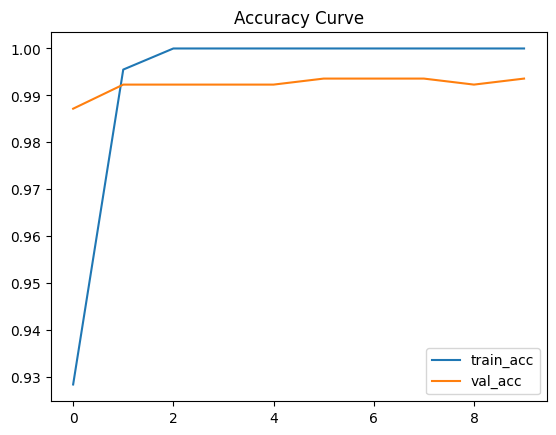

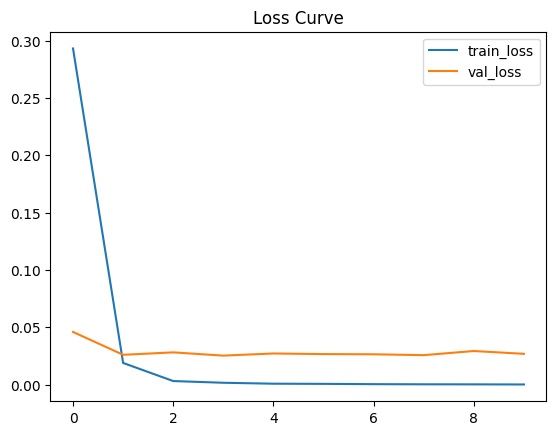

In [ ]:
plt.plot(history.history["accuracy"], label="train_acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.title("Loss Curve")
plt.show()


**the best one is Neural Network**

In [ ]:
def evaluate_model(model, X_test, y_test, name):
    y_pred_proba = model.predict(X_test)
    y_pred = (y_pred_proba > 0.5).astype(int)

    # Ensure y_test is also integer type for classification metrics
    y_test_binary = y_test.astype(int)

    acc  = accuracy_score(y_test_binary, y_pred)
    prec = precision_score(y_test_binary, y_pred, zero_division=0)
    rec  = recall_score(y_test_binary, y_pred, zero_division=0)
    f1   = f1_score(y_test_binary, y_pred, zero_division=0)

    return {
        "Model": name,
        "Accuracy": round(acc, 3),
        "Precision": round(prec, 3),
        "Recall": round(rec, 3),
        "F1-score": round(f1, 3)
    }

results = []

results.append(evaluate_model(model_lr,  X_test_tfidf, y_test, "Logistic Regression"))
results.append(evaluate_model(model,  X_test_tfidf, y_test, "Random Forest"))
results.append(evaluate_model(model_knn, X_test_tfidf, y_test, "KNN"))
results.append(evaluate_model(model,  X_test, y_test, "nn"))
df_results = pd.DataFrame(results)
df_results

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.511,0.525,0.527,0.526
1,Random Forest,0.518,0.528,0.603,0.563
2,KNN,0.539,0.548,0.591,0.569
3,nn,0.998,1.000,0.996,0.998


In [ ]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
sklearn
tensorflow
re

Overwriting requirements.txt
